# DeviceSafe: Learning from Medical Device Failures

The FDA receives a constant stream of reports about medical devices that malfunctioned or were involved in patient harm (the MAUDE database). For anyone designing a device, those reports are free lessons, but they are buried in unstructured narrative text.

DeviceSafe pulls reports for a device type from the [openFDA API](https://open.fda.gov/apis/device/event/), finds the reports most relevant to a design question, and has an LLM synthesise them into a risk review in ISO 14971 terms, with every claim cited to a report number and the citations checked automatically.

**Case study: infusion pumps.** Oxytocin given by infusion is first-line prevention and treatment for postpartum hemorrhage, so how these pumps fail matters directly for maternal care.

In [ ]:
   import os
   os.environ["ANTHROPIC_API_KEY"] = "goes here"

In [2]:
# Setup: works locally (run from notebooks/) and in Google Colab
import os, sys
if "google.colab" in sys.modules and not os.path.exists("devicesafe"):
    !git clone https://github.com/Ebby-L/devicesafe.git
    %cd devicesafe
    !pip -q install anthropic
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

# Optional: an Anthropic API key enables the LLM review. Without one, you get an extractive summary.
# In Colab, add ANTHROPIC_API_KEY under Secrets (the key icon in the left bar).
try:
    from google.colab import userdata
    os.environ.setdefault("ANTHROPIC_API_KEY", userdata.get("ANTHROPIC_API_KEY") or "")
except Exception:
    pass

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from devicesafe.openfda import count_by, fetch_events
from devicesafe.retrieval import problem_frequencies
from devicesafe.review import review

DEVICE = "infusion pump"
EXCLUDE = ["insulin"]   # insulin pumps are diabetes devices, not the IV pumps used for oxytocin
SINCE = "20230101"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. The size of the picture

A plain search for "infusion pump" also returns insulin pumps, which are diabetes devices with different failure modes. They are excluded so the analysis covers general-purpose IV pumps, the kind used to give oxytocin. These counts are computed by openFDA across **all** matching reports, not just the sample fetched below.

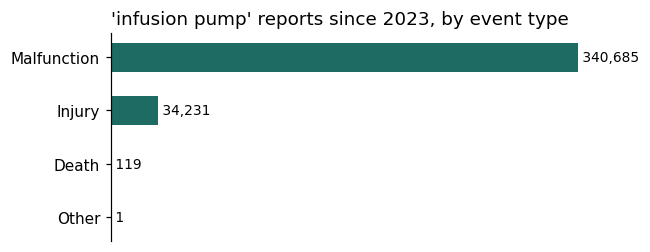

In [3]:
types = pd.Series(count_by(DEVICE, "event_type.exact", since=SINCE, exclude=EXCLUDE)).sort_values()
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(types.index, types.values, color="#1d6b62", height=0.55)
for y, v in enumerate(types.values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9)
ax.set_title(f"'{DEVICE}' reports since {SINCE[:4]}, by event type", loc="left")
ax.xaxis.set_visible(False); ax.spines["bottom"].set_visible(False)
plt.tight_layout(); plt.show()

## 2. Fetch a working sample

The most recent reports, with their narratives.

In [4]:
events = fetch_events(DEVICE, limit=500, since=SINCE, exclude=EXCLUDE)
df = pd.DataFrame([{"report": e.report_number, "date": e.date_received, "type": e.event_type,
                    "brand": e.brand_name, "problems": "; ".join(e.product_problems),
                    "narrative": e.narrative[:120]} for e in events])
print(f"{len(events)} reports fetched, {sum(bool(e.narrative) for e in events)} with narrative text")
df.head()

500 reports fetched, 172 with narrative text


,report,date,type,brand,problems,narrative
0,3010293992-2026-00091,20260930,Malfunction,Avoset Infusion Pump US,Infusion or Flow Problem,This complaint was reported by a customer from...
1,3016798778-2026-00558,20260930,Malfunction,twiist Automated Insulin Delivery System,"Pumping Stopped; Noise, Audible",
2,3016798778-2026-00553,20260930,Malfunction,twiist Automated Insulin Delivery System,Failure to Pump,
3,3016798778-2026-00556,20260930,Malfunction,twiist Automated Insulin Delivery System,Failure to Pump,
4,3016798778-2026-00552,20260930,Malfunction,twiist Automated Insulin Delivery System,Failure to Pump,


In [5]:
# Check the filter worked: which device types made it into the sample?
pd.Series([e.generic_name for e in events]).value_counts().head(10)

Infusion Pump                       326
INFUSION PUMP SYSTEM                128
Enteral Infusion Pump                34
Infusion Pump and Accessory Sets     11
Freedom60 Infusion Pump               1
Name: count, dtype: int64

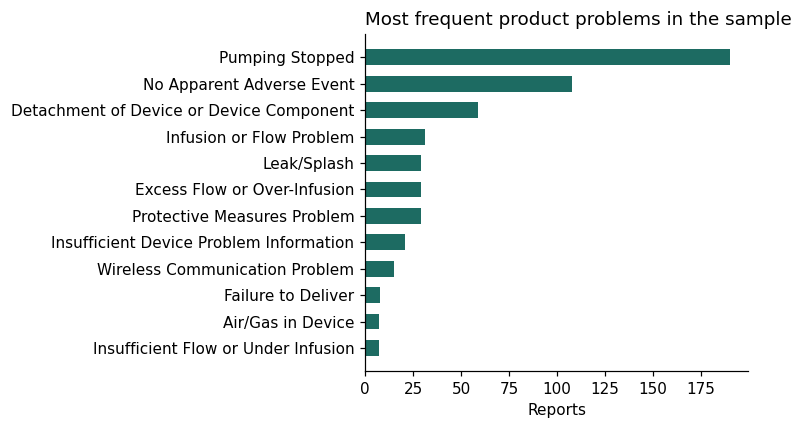

In [6]:
probs = pd.DataFrame(problem_frequencies(events, 12), columns=["problem", "reports"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(probs["problem"], probs["reports"], color="#1d6b62", height=0.6)
ax.set_title("Most frequent product problems in the sample", loc="left")
ax.set_xlabel("Reports")
plt.tight_layout(); plt.show()

## 3. Ask a design question

The review retrieves the most relevant narratives with TF-IDF, sends only those to the LLM, and instructs it to cite every claim, stay inside the evidence and never infer incidence rates (MAUDE cannot support them).

In [7]:
QUESTION = "What failure modes could lead to over-infusion or under-infusion of a high-alert drug such as oxytocin?"
result = review(DEVICE, events, QUESTION, k=12)
display(Markdown(result["answer"]))

**Scope note:** None of the supplied reports involves oxytocin, labor and delivery, or an obstetric setting. The drugs named are treprostinil [3016798778-2026-00377], sodium bicarbonate [50327774], paclitaxel [50523919] and docetaxel [50523912]. Several reports do not name the drug [3010293992-2026-00086]. Findings below are general infusion-pump patterns, not oxytocin-specific evidence. MAUDE reports are unverified and under-reported, so nothing here indicates frequency or relative safety.

## 1. Recurring failure modes

- **Pump stops with an alarm (under-infusion by interruption):**
  - Four RemunityPRO reports describe "Pump Failure" alarms [3016798778-2026-00377, 3016798778-2026-00365, 3016798778-2026-00266, 3016798778-2026-00366].
  - An Agilia VP MC reported a "motor failure" error [50455250].
  - Root cause is not stated in any of these.
- **Recovery or backup failure:**
  - Patients had misplaced the backup pump [3016798778-2026-00377, 3016798778-2026-00366].
  - Alarms could not be resolved by the user [3016798778-2026-00365].
  - A forgotten system passcode prevented titration back to the correct rate after a restart [3016798778-2026-00266].
  - Replacement systems were shipped in all four RemunityPRO reports.
- **Unspecified "delivery issues" on Sapphire/Avoset pumps:**
  - These are coded as over-infusion [3010293992-2026-00079], under-infusion [3010293992-2026-00088], and general flow problem [3010293992-2026-00086, 3010293992-2026-00091].
  - No mechanism, drug, or harm is given in any of them.
- **Single-report signal, not a recurring pattern:** An Agilia pump displayed "infusion in progress" while no solution flowed [50327774]. Its product problem is coded "Excess Flow or Over-Infusion," which conflicts with the no-flow narrative. The cause is not visible in the excerpt.
- **Coding noise:** Two Volumat reports coded "Infusion or Flow Problem" describe drug adverse reactions (paclitaxel, docetaxel) with the infusion interrupted and later resumed. No device malfunction is described [50523919, 50523912]. I would not treat them as evidence of a flow failure mode.

## 2. Hazard chains

**A. Unrecoverable pump stop → loss of therapy**
- Hazard: pump failure alarm and stoppage [3016798778-2026-00366].
- Hazardous situation: no usable backup, so there is no continuous delivery [3016798778-2026-00366, 3016798778-2026-00377].
- Harm: hospital admission for alternative IV therapy [3016798778-2026-00366].
- The drug in these reports is treprostinil. Whether an equivalent interruption of oxytocin would cause harm is not addressed by these reports.

**B. Restart without ability to re-establish the prescribed rate → sustained under-dosing**
- Hazard: a cassette change restarted the infusion, but the passcode was forgotten [3016798778-2026-00266].
- Hazardous situation: delivery below the prescribed rate, with no means to titrate up.
- Harm: extended time off therapy and hospital admission [3016798778-2026-00266].

**C. Run indication without flow → undetected under-infusion**
- Hazard: the display shows the infusion in progress while no solution flows [50327774].
- Hazardous situation: the clinician is led to believe delivery is occurring.
- Harm: no harm occurred in this report. The chain is potential only. It is unknown whether an occlusion or other alarm was expected or absent.

**D. Over-infusion**
- Only one provided report is coded as over-infusion, and it gives no mechanism or harm [3010293992-2026-00079]. A hazard chain cannot be built from these reports.

## 3. Design and usability implications

These are proposed controls inferred from the failure patterns. The reports do not say they would have prevented the events.

- **Alarm and recovery path:** Make pump-failure alarms actionable, with a clear on-screen recovery sequence and a defined fail-safe state [3016798778-2026-00365]. Verify in usability testing that lay and clinical users can resolve or escalate alarms.
- **Backup readiness:** Evaluate prompts or labeling that keep a backup pump accessible, since misplaced backups figure in two reports [3016798778-2026-00377, 3016798778-2026-00366].
- **Credential and rate-restoration usability:** Assess whether passcode lockout can block return to the prescribed rate after a restart [3016798778-2026-00266]. Consider recovery or override paths, and a restart prompt that shows the programmed rate versus the current rate.
- **Flow verification:** Consider whether "running" status should be corroborated by flow or occlusion sensing. Run a fault-tree analysis on a "running with no flow" state [50327774].
- **Over/under-infusion fault analysis:** Include these fault classes in the FMEA for each pump platform [3010293992-2026-00079, 3010293992-2026-00088]. Require complaint records to capture the drug and mechanism.
- **Failure logging:** Log motor and other error codes with enough detail to support root-cause analysis [50455250].

## 4. Evidence gaps

- No oxytocin, obstetric, or high-alert-drug-specific over-infusion event appears in the supplied reports. Drugs differ in half-life and titration needs, so harm from interruption cannot be transferred from treprostinil to oxytocin.
- Root causes are largely absent. The reports have no investigation conclusions, and several are marked as needing more information [50455250, 50523919]. The text of [50327774] is truncated.
- The over-infusion and under-infusion reports provide no mechanism, drug, rate, or duration [3010293992-2026-00079, 3010293992-2026-00088].
- The product-problem counts in the context (for example, Pumping Stopped 190 of 500) describe only the fetched set. They cannot be read as rates or as comparisons between devices.
- The pump types differ (ambulatory, hospital large-volume, syringe-type), so findings may not generalize to a given design.
- Product-problem coding is inconsistent with some narratives [50327774, 50523919, 50523912].

In [8]:
print(result["mode"], len(result["answer"]))
print(result["answer"][:800])

llm 5910
**Scope note:** None of the supplied reports involves oxytocin, labor and delivery, or an obstetric setting. The drugs named are treprostinil [3016798778-2026-00377], sodium bicarbonate [50327774], paclitaxel [50523919] and docetaxel [50523912]. Several reports do not name the drug [3010293992-2026-00086]. Findings below are general infusion-pump patterns, not oxytocin-specific evidence. MAUDE reports are unverified and under-reported, so nothing here indicates frequency or relative safety.

## 1. Recurring failure modes

- **Pump stops with an alarm (under-infusion by interruption):**
  - Four RemunityPRO reports describe "Pump Failure" alarms [3016798778-2026-00377, 3016798778-2026-00365, 3016798778-2026-00266, 3016798778-2026-00366].
  - An Agilia VP MC reported a "motor failure" error 


## 4. Check the citations

An LLM can invent references. Every report number in the answer is checked against the reports actually supplied.

In [9]:
c = result["citations"]
print(f"Mode: {result['mode']} | valid citations: {len(c['valid'])} | unrecognised: {len(c['unknown'])}")
if c["unknown"]:
    print("Unrecognised:", c["unknown"])
pd.DataFrame(result["sources"])

Mode: llm | valid citations: 11 | unrecognised: 0


,report_number,date,event_type,score
0,50455250,20260826,Malfunction,0.088
1,3016798778-2026-00377,20260827,Malfunction,0.080
2,50327774,20260819,Malfunction,0.080
3,3016798778-2026-00365,20260827,Malfunction,0.076
4,3016798778-2026-00266,20260814,Injury,0.074
5,50523919,20260831,Injury,0.070
6,3016798778-2026-00366,20260827,Injury,0.069
7,50523912,20260831,Injury,0.069
8,3010293992-2026-00086,20260917,Malfunction,0.067
9,3010293992-2026-00079,20260914,Malfunction,0.065


## 5. Try another question

In [10]:
display(Markdown(review(DEVICE, events, "How do alarm failures show up, and what was the consequence for the patient?")["answer"]))

## 1. Recurring failure modes

**A. Alarm did not annunciate (protective measure failed).** Three Moog/MMD reports describe an alarm that failed to operate.
- The no-flow-out alarm failed when the pump was returned for evaluation, in a pump reported with broken hinges [1722139-2026-00263].
- The no-flow-out alarm failed on evaluation of a pump the reporter said was alarming persistently [1722139-2026-00264]. The field report and the bench result conflict, and the reports don't explain why.
- The auxiliary alarm failed after fluid ingress [1722139-2026-00260].
- All three were found during evaluation or testing. No patient effect was reported [1722139-2026-00263, 1722139-2026-00264], and no patient was involved in the third [1722139-2026-00260].

**B. Alarm fired for an unresolvable pump failure, and delivery stopped.**
- The twiist system gave a "Pump Error" the user could not resolve in four reports [3016798778-2026-00511, 3016798778-2026-00474, 3016798778-2026-00472, 3016798778-2026-00481]. In one, the error followed troubleshooting of a Line Blocked alarm [3016798778-2026-00511].
- RemunityPRO gave a "Pump Failure" alarm in two reports [3016798778-2026-00377, 3016798778-2026-00366]. A third reported an alarm of unspecified type [3016798778-2026-00364].
- The resolution in every case was replacement hardware or a backup therapy.

**C. Dependence on a backup that wasn't available or also failed.**
- The backup RemunityPRO system gave the same alarm [3016798778-2026-00364].
- The backup pump was misplaced in two reports [3016798778-2026-00366, 3016798778-2026-00377].
- twiist users switched to backup insulin therapy while awaiting a replacement [3016798778-2026-00474, 3016798778-2026-00472, 3016798778-2026-00481].

**D. Occlusion alarms with no reported harm.** Two Agilia reports describe an upstream occlusion alarm with no adverse event reported [3000240707-2026-00324, 50349593]. They carry identical text and may be duplicates. Both say further information is needed.

## 2. Hazard chains

**Chain 1: delivery stops, and no working backup is available.**
- **Hazard:** unresolvable pump failure or error alarm that stops delivery [3016798778-2026-00366, 3016798778-2026-00474].
- **Hazardous situation:** the user has no functioning alternative, either because the backup was misplaced [3016798778-2026-00366], the backup alarmed identically [3016798778-2026-00364], or the user was at work without insulin until the end of the shift [3016798778-2026-00474].
- **Harm reported:**
  - Hospital admission to receive IV Remodulin [3016798778-2026-00366].
  - ED presentation and admission for pulmonary hypertension symptoms, with later discharge [3016798778-2026-00364]. The report records the patient's own account, and causation is not established.
  - Glucose of 300 mg/dL, with no EMS needed [3016798778-2026-00472].

**Chain 2: protective alarm fails silently (inferred, not observed in patients).**
- **Hazard:** the no-flow or auxiliary alarm fails to operate [1722139-2026-00263, 1722139-2026-00264, 1722139-2026-00260].
- **Hazardous situation:** a flow stoppage or fluid ingress goes unannounced during use. This is my extrapolation. The reports describe the alarm failure only on evaluation or in testing.
- **Potential harm:** undetected interruption of therapy. No harm was reported in these cases.

## 3. Design and usability implications

These are proposals derived from the patterns above, not requirements stated in the reports.

1. **Alarm path verification.** Add a power-on or periodic self-test of the alarm path (sensing, logic and annunciator), and test it after mechanical or ingress events. Three reports show alarms failing in units with a hinge fault, a persistent-alarm complaint, or fluid ingress [1722139-2026-00263, 1722139-2026-00264, 1722139-2026-00260].
2. **Ingress and mechanical protection.** Make alarm function robust to fluid ingress, and consider detecting damaged hinges and flagging the pump out of service [1722139-2026-00260, 1722139-2026-00263].
3. **Independent alarm.** Where fluid ingress can defeat the primary alarm, assess whether the auxiliary alarm shares the same failure path [1722139-2026-00260].
4. **Actionable unresolvable-error alarms.** When a pump error cannot be cleared, the alarm should state the next step: switch to backup, or call for replacement. Distinguish the error code from the preceding alarm, since a Line Blocked alarm escalated into a Pump Error during troubleshooting [3016798778-2026-00511].
5. **Backup readiness.** For therapies with no tolerance for interruption, consider:
   - a prompt to confirm the backup is on hand and functional;
   - a locate or carry reminder;
   - replacement logistics sized to the therapy's time-critical nature [3016798778-2026-00366, 3016798778-2026-00377, 3016798778-2026-00364].
6. **Common-cause analysis for backups.** The backup gave the same alarm as the primary [3016798778-2026-00364]. Assess whether primary and backup share a failure cause, such as the same software state, lot or accessory.
7. **Occlusion alarm clarity.** Make upstream occlusion alarms identify the likely site and the resolution steps, to reduce reliance on manufacturer follow-up [3000240707-2026-00324].

## 4. Evidence gaps

- **Root cause.** None of the reports gives a root cause for the pump errors, the failed alarms, or the discrepancy between the field complaint and the bench result [1722139-2026-00264].
- **Alarm detail.** The alarm type is unspecified for one RemunityPRO event [3016798778-2026-00364]. No report states alarm audibility, how long delivery was interrupted, or how long the user took to notice.
- **Causation.** Whether the symptoms in [3016798778-2026-00364] or the glucose reading in [3016798778-2026-00472] were caused by the interruption is not established.
- **Evaluation findings.** No report gives manufacturer evaluation findings for the twiist, RemunityPRO, or Agilia events. The Agilia reports state that investigation is incomplete [3000240707-2026-00324, 50349593].
- **Scope.** This analysis covers only the 12 reports shown, out of 500 fetched. Product-problem counts from the wider set cannot be mapped to alarm behavior without the underlying text. MAUDE data are unverified and under-reported. Nothing here supports incidence or comparative conclusions across devices or manufacturers.

## Limitations

- **MAUDE is not a rate source.** Reports are voluntary or mandated but unverified, under-reported and sometimes duplicated. They show what *can* go wrong, never how often.
- **Generic-name search is imperfect.** Manufacturers label devices inconsistently, so some relevant reports are missed and a few unrelated ones slip in.
- **Retrieval is lexical.** TF-IDF matches words, not meaning. Embedding-based retrieval would catch paraphrased descriptions.
- **The LLM synthesises; it does not verify.** Citations are checked automatically, but conclusions still need an engineer's reading of the source reports.

## Next steps

- Embedding retrieval with a re-ranker
- Map findings to a structured hazard log template for design reviews
- Add device classes relevant to low-resource maternity care: fetal monitors, BP monitors, pulse oximeters